# Session Time 이상치 제거 분석

실무에서 수행한 Session Time 분석 코드를 기반으로 작성한 공개용 Notebook입니다.

- 실제 회사 데이터 및 내부 식별 정보 제외
- 공개용 합성 데이터 사용
- 원본 분석 순서 및 코드 구조 최대한 유지
- 내부 컬럼명과 콘텐츠 정보만 일반화


In [1]:
### 라이브러리 호출

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from pathlib import Path


### 공개용 데이터 경로 설정

path = Path("../sample_data/")


### 공개용 합성 데이터 호출

sample = pd.read_csv(path / "sample_sessiontime.csv")


### 주차별 로그 통합 구조 재현

all_result = []

for week in sorted(sample["week"].unique()):
    df_week = sample[sample["week"] == week][
        [
            "week",
            "date",
            "content_id",
            "set_id",
            "user_id",
            "scroll_segment",
            "session_time",
            "content_length",
        ]
    ].copy()

    all_result.append(df_week)

final = pd.concat(all_result, ignore_index=True)

final


/home/oai/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-j574_ck5 because there was an issue with the default path (/home/oai/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


,week,date,content_id,set_id,user_id,scroll_segment,session_time,content_length
0,25Y W05,2025-02-05,content_003,set_003,user_0006,50-75%,32.5,2200
1,25Y W05,2025-02-05,content_005,set_005,user_0076,COMPLETE,79.2,2600
2,25Y W05,2025-02-05,content_002,set_002,user_0084,OUT,0.2,1400
3,25Y W05,2025-02-05,content_008,set_008,user_0210,0-25%,0.5,2000
4,25Y W05,2025-02-05,content_005,set_005,user_0222,50-75%,35.7,2600
...,...,...,...,...,...,...,...,...
1245,25Y W12,2025-03-20,content_005,set_005,user_1223,COMPLETE,103.0,2600
1246,25Y W12,2025-03-24,content_002,set_002,user_1224,0-25%,30.2,1400
1247,25Y W12,2025-03-20,content_006,set_006,user_1231,COMPLETE,115.6,1600
1248,25Y W12,2025-03-21,content_002,set_002,user_1233,OUT,9.8,1400


In [2]:
### 콘텐츠 메타데이터 구성

c_list = (
    sample[
        [
            "week",
            "content_id",
            "section",
            "slot",
            "curation_type",
            "app_type",
            "content_type",
            "content_name",
            "content_group",
        ]
    ]
    .drop_duplicates()
    .rename(
        columns={
            "week": "Week",
            "content_id": "ContentKey",
        }
    )
)


### 결합 키 정리

c_list["Week"] = c_list["Week"].astype(str).str.strip()
c_list["ContentKey"] = c_list["ContentKey"].astype(str).str.strip()

final["week"] = final["week"].astype(str).str.strip()
final["content_id"] = final["content_id"].astype(str).str.strip()


### 결측치 처리 및 확인

final["session_time"] = final["session_time"].fillna(0)

final.isnull().sum()


week              0
date              0
content_id        0
set_id            0
user_id           0
scroll_segment    0
session_time      0
content_length    0
dtype: int64

In [3]:
### 데이터 크기 확인

final.shape


(1250, 8)

In [4]:
### 로그 및 콘텐츠 메타데이터 결합

final_df = final.copy()

final_df = pd.merge(
    final_df,
    c_list,
    right_on=["Week", "ContentKey"],
    left_on=["week", "content_id"],
    how="left",
)

final_df.shape


(1250, 17)

In [5]:
### 분석 컬럼 정리

final_df = final_df[
    [
        "Week",
        "date",
        "section",
        "slot",
        "curation_type",
        "app_type",
        "content_type",
        "content_name",
        "content_group",
        "ContentKey",
        "set_id",
        "user_id",
        "scroll_segment",
        "session_time",
        "content_length",
    ]
]


### 원본 분석 구조에 따른 정수형 변환

final_df["session_time"] = final_df["session_time"].astype(int)

final_df.head()


,Week,date,section,slot,curation_type,app_type,content_type,content_name,content_group,ContentKey,set_id,user_id,scroll_segment,session_time,content_length
0,25Y W05,2025-02-05,depth_2,3,Category_B,Multi,Card,Editorial_C,Group_B,content_003,set_003,user_0006,50-75%,32,2200
1,25Y W05,2025-02-05,depth_2,5,Category_C,Multi,Card,Editorial_E,Group_C,content_005,set_005,user_0076,COMPLETE,79,2600
2,25Y W05,2025-02-05,depth_2,2,Category_A,Single,Card,Editorial_B,Group_A,content_002,set_002,user_0084,OUT,0,1400
3,25Y W05,2025-02-05,depth_2,8,Category_B,Single,Card,Editorial_H,Group_B,content_008,set_008,user_0210,0-25%,0,2000
4,25Y W05,2025-02-05,depth_2,5,Category_C,Multi,Card,Editorial_E,Group_C,content_005,set_005,user_0222,50-75%,35,2600


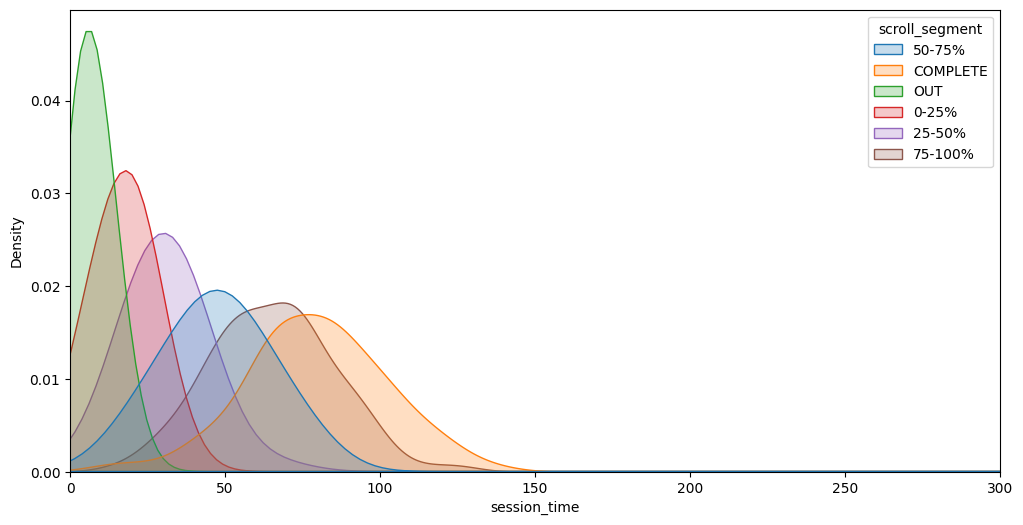

In [6]:
### 스크롤 뎁스별 Session Time 분포 확인

plt.figure(figsize=(12, 6))

sns.kdeplot(
    data=final_df[final_df["session_time"] <= 500],
    x="session_time",
    hue="scroll_segment",
    fill=True,
    common_norm=False,
)

plt.xlim(0, 300)
plt.show()


In [7]:
### Session Time 구간별 비중 확인

total = len(final_df)

count_0_20 = (
    (final_df["session_time"] >= 0)
    & (final_df["session_time"] <= 20)
).sum()

count_21_300 = (
    (final_df["session_time"] >= 21)
    & (final_df["session_time"] <= 300)
).sum()

count_over300 = (
    final_df["session_time"] > 300
).sum()


result = pd.DataFrame(
    {
        "bins": [
            "Total",
            "0s~20s",
            "21s~300s",
            "over300s",
        ],
        "count": [
            total,
            count_0_20,
            count_21_300,
            count_over300,
        ],
    }
)

result["ratio"] = result["count"] / total

result


,bins,count,ratio
0,Total,1250,1.0000
1,0s~20s,500,0.4000
2,21s~300s,743,0.5944
3,over300s,7,0.0056


In [8]:
### 300초 초과 Session 제외

final_df = final_df[
    final_df["session_time"] <= 300
].copy()


### 스크롤 뎁스 구간명 정리

final_df["scroll_segment"] = final_df["scroll_segment"].replace(
    "OUT",
    "즉시 이탈",
)

final_df["scroll_segment"] = final_df["scroll_segment"].replace(
    "0-25%",
    "0% ~ 25%",
)

final_df["scroll_segment"] = final_df["scroll_segment"].replace(
    "25-50%",
    "25% ~ 50%",
)

final_df["scroll_segment"] = final_df["scroll_segment"].replace(
    "50-75%",
    "50% ~ 75%",
)

final_df["scroll_segment"] = final_df["scroll_segment"].replace(
    "75-100%",
    "75% ~ 100%",
)

final_df["scroll_segment"] = final_df["scroll_segment"].replace(
    "COMPLETE",
    "완독",
)


In [9]:
### 콘텐츠 유형별 Session Time 집계

content_summary = (
    final_df.groupby(
        [
            "curation_type",
            "app_type",
            "content_group",
            "content_name",
            "scroll_segment",
        ]
    )[["session_time"]]
    .agg(
        [
            "count",
            "mean",
            "median",
        ]
    )
    .reset_index()
)

content_summary.head(20)


curation_type app_type content_group  ... session_time                  
                                         ...        count       mean median
0     Category_A    Multi       Group_A  ...           18  14.111111   13.5
1     Category_A    Multi       Group_A  ...           24  30.625000   27.0
2     Category_A    Multi       Group_A  ...           22  45.954545   44.0
3     Category_A    Multi       Group_A  ...           15  63.600000   64.0
4     Category_A    Multi       Group_A  ...           20  83.100000   86.5
5     Category_A    Multi       Group_A  ...           41   5.634146    5.0
6     Category_A    Multi       Group_A  ...           36  18.000000   18.5
7     Category_A    Multi       Group_A  ...           19  28.631579   26.0
8     Category_A    Multi       Group_A  ...           23  46.086957   44.0
9     Category_A    Multi       Group_A  ...           23  69.913043   68.0
10    Category_A    Multi       Group_A  ...           14  82.928571   80.5
11    Category_A    Multi       Group_A  ...           31   7.161290    6.0
12    Category_A   Single       Group_A  ...           32  14.812500   16.5
13    Category_A   Single       Group_A  ...           29  31.896552   31.0
14    Category_A   Single       Group_A  ...           16  52.250000   52.5
15    Category_A   Single       Group_A  ...           18  70.277778   70.5
16    Category_A   Single       Group_A  ...           10  71.700000   67.0
17    Category_A   Single       Group_A  ...           42   7.642857    6.5
18    Category_B    Multi       Group_B  ...           33  17.696970   17.0
19    Category_B    Multi       Group_B  ...           23  29.521739   28.0

[20 rows x 8 columns]

In [10]:
### 큐레이션 유형 및 앱 유형별 Session Time 집계

type_summary = (
    final_df.groupby(
        [
            "curation_type",
            "app_type",
            "scroll_segment",
        ]
    )[["session_time"]]
    .agg(
        [
            "count",
            "mean",
            "median",
        ]
    )
    .reset_index()
)

type_summary.head(20)


curation_type app_type scroll_segment session_time                  
                                                count       mean median
0     Category_A    Multi       0% ~ 25%           54  16.703704   17.0
1     Category_A    Multi      25% ~ 50%           43  29.744186   27.0
2     Category_A    Multi      50% ~ 75%           45  46.022222   44.0
3     Category_A    Multi     75% ~ 100%           38  67.421053   67.5
4     Category_A    Multi             완독           34  83.029412   84.0
5     Category_A    Multi          즉시 이탈           72   6.291667    6.0
6     Category_A   Single       0% ~ 25%           32  14.812500   16.5
7     Category_A   Single      25% ~ 50%           29  31.896552   31.0
8     Category_A   Single      50% ~ 75%           16  52.250000   52.5
9     Category_A   Single     75% ~ 100%           18  70.277778   70.5
10    Category_A   Single             완독           10  71.700000   67.0
11    Category_A   Single          즉시 이탈           42   7.642857    6.5
12    Category_B    Multi       0% ~ 25%           33  17.696970   17.0
13    Category_B    Multi      25% ~ 50%           23  29.521739   28.0
14    Category_B    Multi      50% ~ 75%           25  51.680000   52.0
15    Category_B    Multi     75% ~ 100%           23  63.347826   65.0
16    Category_B    Multi             완독           17  79.058824   80.0
17    Category_B    Multi          즉시 이탈           34   7.411765    6.5
18    Category_B   Single       0% ~ 25%           67  18.388060   18.0
19    Category_B   Single      25% ~ 50%           42  30.357143   33.5

In [11]:
### 주차 및 슬롯별 Session Time 집계

weekly_slot_summary = (
    final_df.groupby(
        [
            "Week",
            "slot",
            "curation_type",
            "content_name",
            "scroll_segment",
        ]
    )[["session_time"]]
    .agg(
        [
            "count",
            "median",
            "mean",
        ]
    )
    .reset_index()
)

weekly_slot_summary.head(20)


Week slot curation_type  ... session_time             
                                ...        count median  mean
0   25Y W05    2    Category_A  ...            2   39.0  39.0
1   25Y W05    2    Category_A  ...            2    3.0   3.0
2   25Y W05    3    Category_B  ...            1   48.0  48.0
3   25Y W05    3    Category_B  ...            1   32.0  32.0
4   25Y W05    3    Category_B  ...            1   16.0  16.0
5   25Y W05    4    Category_B  ...            2   31.0  31.0
6   25Y W05    4    Category_B  ...            1   66.0  66.0
7   25Y W05    4    Category_B  ...            1   11.0  11.0
8   25Y W05    5    Category_C  ...            1    0.0   0.0
9   25Y W05    5    Category_C  ...            1   35.0  35.0
10  25Y W05    5    Category_C  ...            1   79.0  79.0
11  25Y W05    5    Category_C  ...            1   20.0  20.0
12  25Y W05    6    Category_C  ...            1   23.0  23.0
13  25Y W05    6    Category_C  ...            1   17.0  17.0
14  25Y W05    7    Category_A  ...            1   12.0  12.0
15  25Y W05    8    Category_B  ...            2    9.0   9.0
16  25Y W05    8    Category_B  ...            1   75.0  75.0
17  25Y W06    1    Category_A  ...            1   18.0  18.0
18  25Y W06    1    Category_A  ...            2   51.0  51.0
19  25Y W06    1    Category_A  ...            3   50.0  45.0

[20 rows x 8 columns]

In [12]:
### 주차별 Session Time 집계

weekly_summary = (
    final_df.groupby(
        [
            "Week",
            "curation_type",
            "app_type",
            "scroll_segment",
        ]
    )[["session_time"]]
    .agg(
        [
            "count",
            "median",
            "mean",
        ]
    )
    .reset_index()
)

weekly_summary.head(20)


Week curation_type app_type  ... session_time                  
                                    ...        count median       mean
0   25Y W05    Category_A    Multi  ...            1   12.0  12.000000
1   25Y W05    Category_A   Single  ...            2   39.0  39.000000
2   25Y W05    Category_A   Single  ...            2    3.0   3.000000
3   25Y W05    Category_B    Multi  ...            1   48.0  48.000000
4   25Y W05    Category_B    Multi  ...            1   32.0  32.000000
5   25Y W05    Category_B    Multi  ...            1   16.0  16.000000
6   25Y W05    Category_B   Single  ...            2    9.0   9.000000
7   25Y W05    Category_B   Single  ...            2   31.0  31.000000
8   25Y W05    Category_B   Single  ...            2   70.5  70.500000
9   25Y W05    Category_B   Single  ...            1   11.0  11.000000
10  25Y W05    Category_C    Multi  ...            1    0.0   0.000000
11  25Y W05    Category_C    Multi  ...            1   35.0  35.000000
12  25Y W05    Category_C    Multi  ...            1   79.0  79.000000
13  25Y W05    Category_C    Multi  ...            1   20.0  20.000000
14  25Y W05    Category_C   Single  ...            1   23.0  23.000000
15  25Y W05    Category_C   Single  ...            1   17.0  17.000000
16  25Y W06    Category_A    Multi  ...            4   15.5  20.750000
17  25Y W06    Category_A    Multi  ...            8   27.0  31.125000
18  25Y W06    Category_A    Multi  ...            4   44.0  43.250000
19  25Y W06    Category_A    Multi  ...            6   67.0  70.166667

[20 rows x 7 columns]

In [13]:
### 후속 콘텐츠 단위 집계 구조 재현

raw = sample.copy()

raw["scroll_segment"] = raw["scroll_segment"].replace(
    "OUT",
    "즉시 이탈",
)

raw["scroll_segment"] = raw["scroll_segment"].replace(
    "0-25%",
    "0% ~ 25%",
)

raw["scroll_segment"] = raw["scroll_segment"].replace(
    "25-50%",
    "25% ~ 50%",
)

raw["scroll_segment"] = raw["scroll_segment"].replace(
    "50-75%",
    "50% ~ 75%",
)

raw["scroll_segment"] = raw["scroll_segment"].replace(
    "75-100%",
    "75% ~ 100%",
)

raw["scroll_segment"] = raw["scroll_segment"].replace(
    "COMPLETE",
    "완독",
)


### 공개용 콘텐츠명 구성

raw["Title"] = raw["content_name"]


### 콘텐츠 유형 및 스크롤 뎁스별 Session Time 집계

raw_summary = (
    raw.groupby(
        [
            "content_type",
            "Title",
            "scroll_segment",
        ]
    )["session_time"]
    .agg(
        [
            "count",
            "mean",
            "median",
        ]
    )
    .reset_index()
)

raw_summary.head(20)


,content_type,Title,scroll_segment,count,mean,median
0,Card,Editorial_A,0% ~ 25%,19,31.800000,15.60
1,Card,Editorial_A,25% ~ 50%,24,30.970833,27.55
2,Card,Editorial_A,50% ~ 75%,22,46.450000,44.80
3,Card,Editorial_A,75% ~ 100%,15,63.953333,64.10
4,Card,Editorial_A,완독,20,83.535000,86.95
5,Card,Editorial_A,즉시 이탈,42,13.547619,5.50
6,Card,Editorial_B,0% ~ 25%,32,15.275000,17.00
7,Card,Editorial_B,25% ~ 50%,30,44.173333,32.05
8,Card,Editorial_B,50% ~ 75%,16,52.718750,53.00
9,Card,Editorial_B,75% ~ 100%,19,114.631579,73.00


## 체류시간 이상치 제거 기준 설정


In [14]:
### 이상치 분석 데이터 구성

df = sample[
    [
        "content_id",
        "set_id",
        "user_id",
        "scroll_segment",
        "session_time",
        "content_length",
        "content_type",
        "content_name",
    ]
].copy()

df.replace(
    {
        "scroll_segment": {
            "OUT": 0,
        }
    },
    inplace=True,
)

df.head()


,content_id,set_id,user_id,scroll_segment,session_time,content_length,content_type,content_name
0,content_002,set_002,user_0001,0,7.3,1400,Card,Editorial_B
1,content_002,set_002,user_0002,50-75%,59.2,1400,Card,Editorial_B
2,content_002,set_002,user_0003,50-75%,55.0,1400,Card,Editorial_B
3,content_001,set_001,user_0004,25-50%,33.1,1800,Card,Editorial_A
4,content_007,set_007,user_0005,0,0.5,1100,List,Editorial_G


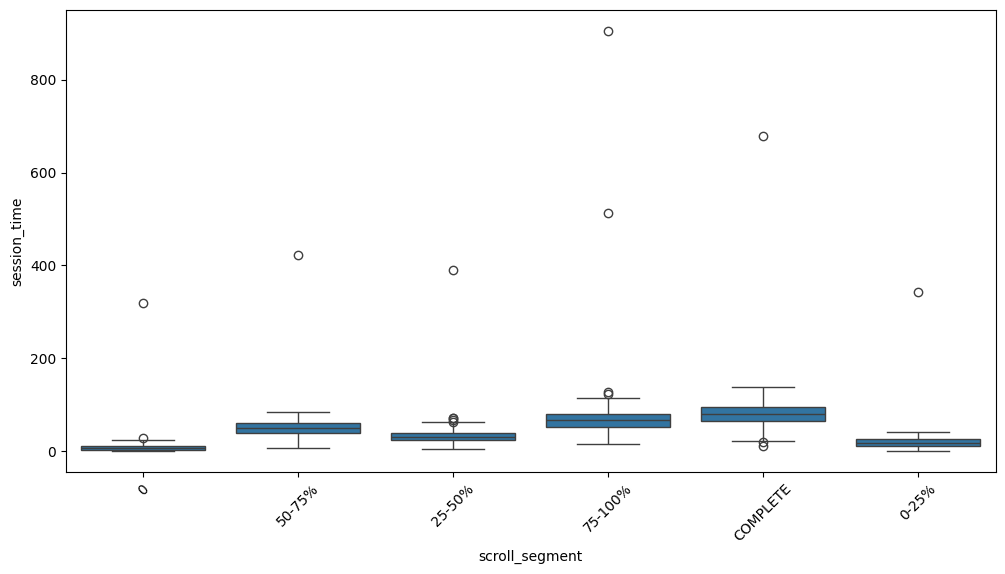

In [15]:
### 스크롤 뎁스별 Session Time Boxplot 확인

plt.figure(figsize=(12, 6))

sns.boxplot(
    x="scroll_segment",
    y="session_time",
    data=df,
)

plt.xticks(rotation=45)
plt.show()


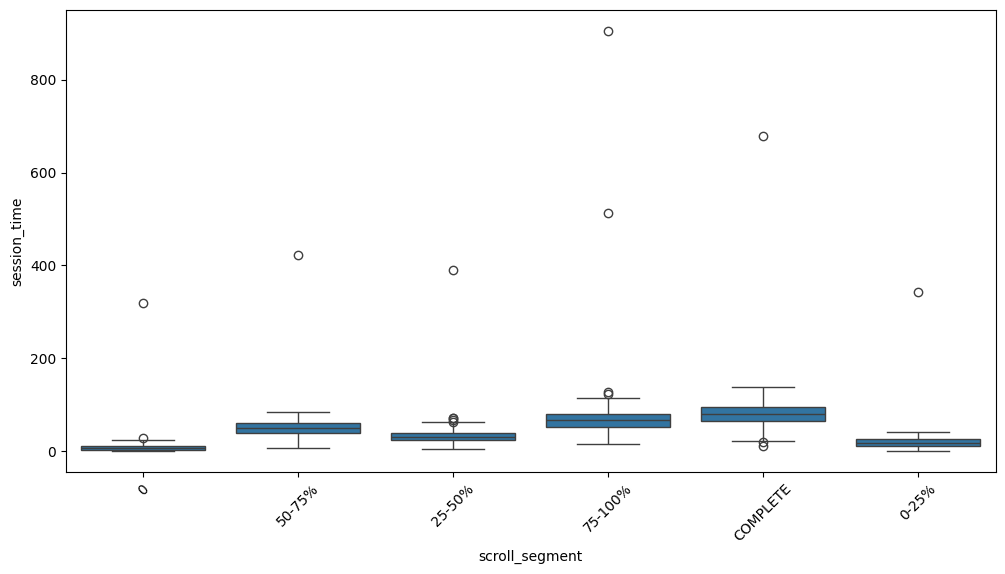

In [16]:
### 극단값 범위 제한 후 Boxplot 확인

plt.figure(figsize=(12, 6))

sns.boxplot(
    x="scroll_segment",
    y="session_time",
    data=df[df["session_time"] < 10000],
)

plt.xticks(rotation=45)
plt.show()


/tmp/ipykernel_796/1921239231.py:5: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(


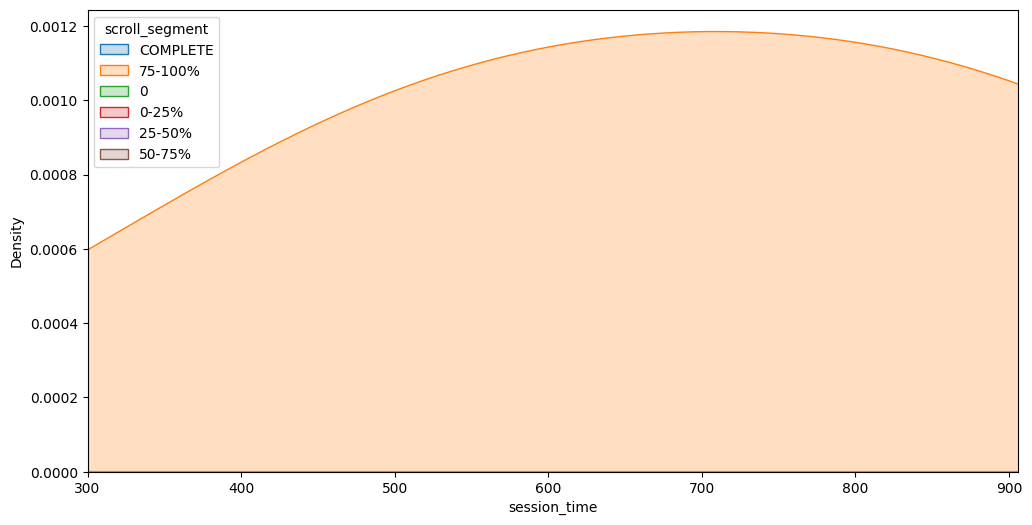

In [17]:
### 300초 초과 Session 분포 확인

plt.figure(figsize=(12, 6))

sns.kdeplot(
    data=df[df["session_time"] > 300],
    x="session_time",
    hue="scroll_segment",
    fill=True,
    common_norm=False,
)

plt.xlim(
    300,
    df["session_time"].max(),
)

plt.show()


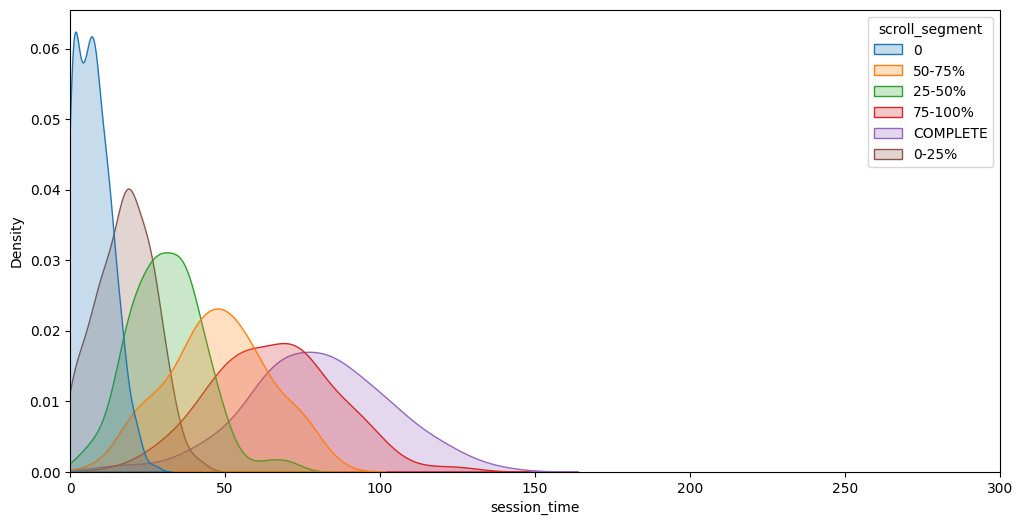

In [18]:
### 300초 이하 Session 데이터 구성

df_300 = df[
    df["session_time"] <= 300
].copy()


### 300초 이하 Session 분포 확인

plt.figure(figsize=(12, 6))

sns.kdeplot(
    data=df_300,
    x="session_time",
    hue="scroll_segment",
    fill=True,
    common_norm=False,
)

plt.xlim(0, 300)
plt.show()


In [19]:
### 5초 단위 Session Time 구간 생성

last_bin = max(
    300,
    int(np.ceil(df_300["session_time"].max())),
)

bins = list(
    range(
        0,
        last_bin + 5,
        5,
    )
)

labels = [
    f"{i}~{i+5}s"
    for i in bins[:-1]
]

df_300["sessiontime_seg"] = pd.cut(
    df_300["session_time"],
    bins=bins,
    labels=labels,
    include_lowest=True,
)

df_300[
    [
        "session_time",
        "sessiontime_seg",
    ]
].head()


,session_time,sessiontime_seg
0,7.3,5~10s
1,59.2,55~60s
2,55.0,50~55s
3,33.1,30~35s
4,0.5,0~5s


In [20]:
### 콘텐츠 길이 및 스크롤 뎁스별 Session Time 집계

length_summary = (
    df_300.groupby(
        [
            "content_length",
            "scroll_segment",
        ],
        as_index=False,
    )["session_time"]
    .agg(
        [
            "count",
            "mean",
        ]
    )
    .reset_index()
)

length_summary.head(20)


,index,content_length,scroll_segment,count,mean
0,0,1100,0,31,7.561290
1,1,1100,0-25%,36,18.394444
2,2,1100,25-50%,19,29.100000
3,3,1100,50-75%,23,46.604348
4,4,1100,75-100%,23,70.386957
5,5,1100,COMPLETE,14,83.407143
6,6,1200,0,35,6.491429
7,7,1200,0-25%,32,20.478125
8,8,1200,25-50%,30,30.490000
9,9,1200,50-75%,26,45.615385


In [21]:
### 리스트형 콘텐츠 별도 확인

list_type = df_300[
    df_300["content_type"]
    .astype(str)
    .str.contains(
        "List",
        na=False,
    )
].copy()

list_type.head()


,content_id,set_id,user_id,scroll_segment,session_time,content_length,content_type,content_name,sessiontime_seg
4,content_007,set_007,user_0005,0,0.5,1100,List,Editorial_G,0~5s
7,content_007,set_007,user_0008,0,6.6,1100,List,Editorial_G,5~10s
17,content_004,set_004,user_0018,50-75%,84.2,1200,List,Editorial_D,80~85s
18,content_004,set_004,user_0019,75-100%,72.9,1200,List,Editorial_D,70~75s
19,content_004,set_004,user_0020,COMPLETE,59.1,1200,List,Editorial_D,55~60s


In [22]:
### 100초 이하 Session 데이터 구성

df = df[
    df["session_time"] <= 100
].copy()


### Session Time 구간 크기 비교 함수

def analyze_bin_sizes(
    df,
    bin_sizes=[3, 5, 10],
    max_cutoff=100,
):
    result = []

    for bin_size in bin_sizes:

        last_bin = max(
            max_cutoff,
            int(
                np.ceil(
                    df["session_time"].max()
                )
            ),
        )

        bins = list(
            range(
                0,
                last_bin + bin_size,
                bin_size,
            )
        )

        labels = [
            f"{i}~{i+bin_size}s"
            for i in bins[:-1]
        ]

        temp_df = df.copy()

        temp_df["sessiontime_seg"] = pd.cut(
            temp_df["session_time"],
            bins=bins,
            include_lowest=True,
        )

        temp_df["sessiontime_seg"] = (
            temp_df["sessiontime_seg"]
            .astype(str)
        )

        bin_stat = (
            temp_df.groupby(
                ["sessiontime_seg"]
            )["session_time"]
            .agg(
                [
                    "count",
                    "mean",
                ]
            )
            .reset_index()
        )

        summary = (
            bin_stat.groupby(
                "sessiontime_seg"
            )
            .agg(
                num_bins=(
                    "sessiontime_seg",
                    "nunique",
                ),
                total_usr=(
                    "count",
                    "sum",
                ),
                avg_bin_means=(
                    "mean",
                    "mean",
                ),
                std_bin_mean=(
                    "mean",
                    "std",
                ),
                min_count_per_bin=(
                    "count",
                    "min",
                ),
                max_count_per_bin=(
                    "count",
                    "max",
                ),
            )
            .reset_index()
        )

        summary["bin_size"] = bin_size
        result.append(summary)

    result_df = pd.concat(
        result,
        ignore_index=True,
    )

    return result_df


### 3초, 5초, 10초 단위 구간 비교

result = analyze_bin_sizes(
    df,
    bin_sizes=[3, 5, 10],
    max_cutoff=100,
)

result.head(30)


,sessiontime_seg,num_bins,total_usr,avg_bin_means,std_bin_mean,min_count_per_bin,max_count_per_bin,bin_size
0,"(-0.001, 3.0]",1,98,1.054082,NaN,98,98,3
1,"(12.0, 15.0]",1,62,13.359677,NaN,62,62,3
2,"(15.0, 18.0]",1,67,16.700000,NaN,67,67,3
3,"(18.0, 21.0]",1,62,19.548387,NaN,62,62,3
4,"(21.0, 24.0]",1,48,22.343750,NaN,48,48,3
5,"(24.0, 27.0]",1,53,25.607547,NaN,53,53,3
6,"(27.0, 30.0]",1,45,28.462222,NaN,45,45,3
7,"(3.0, 6.0]",1,63,4.511111,NaN,63,63,3
8,"(30.0, 33.0]",1,36,31.291667,NaN,36,36,3
9,"(33.0, 36.0]",1,34,34.482353,NaN,34,34,3


In [23]:
### 최종 적용 기준 확인

final_analysis_df = sample[
    sample["session_time"] <= 300
].copy()

print(
    "300초 초과 Session 제외 건수:",
    len(sample) - len(final_analysis_df),
)

print(
    "300초 초과 Session 제외 비율:",
    round(
        (len(sample) - len(final_analysis_df))
        / len(sample)
        * 100,
        2,
    ),
    "%",
)


300초 초과 Session 제외 건수: 7
300초 초과 Session 제외 비율: 0.56 %
